# Project Title

UPI Digital Payments and Fraud Risk Analytics Using Python


# **Objective(Problem statment)**

1. To analyze UPI transaction data and identify key patterns associated with failed and fraudulent transactions.
2. To clean, transform, and preprocess the UPI dataset for effective analysis.
3. To explore relationships between transaction type, merchant category, amount, sender state, bank, device, network, time of day, and transaction outcomes (success, failure, fraud).
4. To create meaningful visualizations that clearly communicate payment patterns and trends.
5. To identify actionable insights that can help banks and payment platforms improve payment success rates and strengthen fraud monitoring.

# Outcome

1. Identification of the factors associated with failed and fraudulent UPI transactions.
2. Understanding of transaction volume, transaction value, and payment behaviour across transaction types and merchant categories.
3. Identification of states, banks, devices, and networks with higher or lower failure and fraud rates.
4. Analysis of relationships between transaction amount, time of day, weekday or weekend, and transaction outcomes.
5. Development of data-driven recommendations to support payment reliability and fraud monitoring.

# Domain
Finance / Banking - Digital Payments (UPI)

#**Dataset Information**

**Source:** https://www.kaggle.com/datasets/skullagos5246/upi-transactions-2024-dataset?resource=download

**Year / Timeline:** Data collected during 2024 (01-01-2024 to 30-12-2024)

**Dataset Column/features Description:**

**Dataset Size:** 250,000 transaction records and 17 features
**Domain:** Finance / Banking - Digital Payments (UPI)


# Stages for DA Project

## Stage 1 – Problem Definition and Dataset Selection


**NOTE : THINGS TO BE COMPLETED**

In this stage, we define the business problem, understand the UPI dataset (source, size and features), import the required libraries, load the data, and perform an initial exploration of its structure, data types, missing values and duplicates.

# **Inital EDA**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [ ]:
df = pd.read_csv('/content/upi_transactions_2024 - Raw Dataset.csv')

In [ ]:
df.head()



,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0


In [ ]:
df.tail()



,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
249995,TXN0000249996,2024-11-08 22:41:43,Recharge,Food,373,SUCCESS,36-45,26-35,Telangana,ICICI,HDFC,iOS,5G,0,22,Friday,0
249996,TXN0000249997,2024-12-15 02:58:03,P2P,Utilities,2025,SUCCESS,36-45,26-35,Rajasthan,HDFC,Yes Bank,Android,5G,0,2,Sunday,1
249997,TXN0000249998,2024-11-27 16:33:25,P2P,Food,468,SUCCESS,26-35,18-25,West Bengal,ICICI,ICICI,Android,4G,0,16,Wednesday,0
249998,TXN0000249999,2024-01-05 13:31:30,Recharge,Healthcare,284,SUCCESS,18-25,36-45,Andhra Pradesh,Axis,ICICI,iOS,4G,0,13,Friday,0
249999,TXN0000250000,2024-01-17 15:23:07,P2P,Entertainment,531,SUCCESS,18-25,26-35,Telangana,Axis,Yes Bank,Android,4G,0,15,Wednesday,0


In [ ]:
print("Number of Rows   :", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows   : 250000
Number of Columns: 17


In [ ]:
df.columns.tolist()



['transaction id',
 'timestamp',
 'transaction type',
 'merchant_category',
 'amount (INR)',
 'transaction_status',
 'sender_age_group',
 'receiver_age_group',
 'sender_state',
 'sender_bank',
 'receiver_bank',
 'device_type',
 'network_type',
 'fraud_flag',
 'hour_of_day',
 'day_of_week',
 'is_weekend']

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   transaction id      250000 non-null  object
 1   timestamp           250000 non-null  object
 2   transaction type    250000 non-null  object
 3   merchant_category   250000 non-null  object
 4   amount (INR)        250000 non-null  int64 
 5   transaction_status  250000 non-null  object
 6   sender_age_group    250000 non-null  object
 7   receiver_age_group  250000 non-null  object
 8   sender_state        250000 non-null  object
 9   sender_bank         250000 non-null  object
 10  receiver_bank       250000 non-null  object
 11  device_type         250000 non-null  object
 12  network_type        250000 non-null  object
 13  fraud_flag          250000 non-null  int64 
 14  hour_of_day         250000 non-null  int64 
 15  day_of_week         250000 non-null  object
 16  is

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
amount (INR),250000.0,1311.756036,1848.059224,10.0,288.0,629.0,1596.0,42099.0
fraud_flag,250000.0,0.001920,0.043776,0.0,0.0,0.0,0.0,1.0
hour_of_day,250000.0,14.681032,5.188304,0.0,11.0,15.0,19.0,23.0
is_weekend,250000.0,0.285348,0.451581,0.0,0.0,0.0,1.0,1.0


In [ ]:
df.describe(include='object').T

,count,unique,top,freq
transaction id,250000,250000,TXN0000249984,1
timestamp,250000,248610,2024-07-23 21:31:06,3
transaction type,250000,4,P2P,112445
merchant_category,250000,10,Grocery,49966
transaction_status,250000,2,SUCCESS,237624
sender_age_group,250000,5,26-35,87432
receiver_age_group,250000,5,26-35,87864
sender_state,250000,10,Maharashtra,37427
sender_bank,250000,8,SBI,62693
receiver_bank,250000,8,SBI,62378


In [ ]:
print("Total missing values:", df.isnull().sum().sum())
df.isnull().sum()


Total missing values: 0


,0
transaction id,0
timestamp,0
transaction type,0
merchant_category,0
amount (INR),0
transaction_status,0
sender_age_group,0
receiver_age_group,0
sender_state,0
sender_bank,0


In [ ]:
print("Duplicate rows          :", df.duplicated().sum())
print("Duplicate transaction id:", df['transaction id'].duplicated().sum())


Duplicate rows          : 0
Duplicate transaction id: 0


In [ ]:
df.nunique()

,0
transaction id,250000
timestamp,248610
transaction type,4
merchant_category,10
amount (INR),10355
transaction_status,2
sender_age_group,5
receiver_age_group,5
sender_state,10
sender_bank,8


In [ ]:
for col in ['transaction type', 'merchant_category', 'sender_state']:
    print(f"\n{col}")
    print(df[col].value_counts())


transaction type
transaction type
P2P             112445
P2M              87660
Bill Payment     37368
Recharge         12527
Name: count, dtype: int64

merchant_category
merchant_category
Grocery          49966
Food             37464
Shopping         29872
Fuel             25063
Other            24828
Utilities        22338
Transport        20105
Entertainment    20103
Healthcare       12663
Education         7598
Name: count, dtype: int64

sender_state
sender_state
Maharashtra       37427
Uttar Pradesh     30125
Karnataka         29756
Tamil Nadu        25367
Delhi             24870
Telangana         22435
Gujarat           20061
Andhra Pradesh    20006
Rajasthan         19981
West Bengal       19972
Name: count, dtype: int64


In [ ]:
print("Fraud flag %:")
print((df['fraud_flag'].value_counts(normalize=True) * 100).round(3))
print("\nTransaction status %:")
print((df['transaction_status'].value_counts(normalize=True) * 100).round(2))


Fraud flag %:
fraud_flag
0    99.808
1     0.192
Name: proportion, dtype: float64

Transaction status %:
transaction_status
SUCCESS    95.05
FAILED      4.95
Name: proportion, dtype: float64


In [ ]:
df_raw = df.copy()


## Stage 2 – Data Cleaning and Pre-processing

In this stage, the UPI dataset is cleaned and prepared for analysis. Missing values and duplicates are checked, column names are standardized, outliers in the transaction amount are treated, skewness is checked and corrected with a log transformation, data types are converted, and new derived features (date parts, time of day, amount category, same bank flag and failed transaction flag) are created.


In [ ]:
print(df.isnull().sum())
print("\nTotal missing:", df.isnull().sum().sum())


transaction id        0
timestamp             0
transaction type      0
merchant_category     0
amount (INR)          0
transaction_status    0
sender_age_group      0
receiver_age_group    0
sender_state          0
sender_bank           0
receiver_bank         0
device_type           0
network_type          0
fraud_flag            0
hour_of_day           0
day_of_week           0
is_weekend            0
dtype: int64

Total missing: 0


In [ ]:
rows_before = df.shape[0]
df = df.drop_duplicates()
df = df.drop_duplicates(subset='transaction id')
print("Rows before:", rows_before)
print("Rows after :", df.shape[0])
print("Duplicates removed:", rows_before - df.shape[0])

Rows before: 250000
Rows after : 250000
Duplicates removed: 0


In [ ]:
df.columns = (df.columns.str.strip()
                        .str.lower()
                        .str.replace(r'[^a-z0-9]+', '_', regex=True)
                        .str.strip('_'))
df.columns.tolist()


['transaction_id',
 'timestamp',
 'transaction_type',
 'merchant_category',
 'amount_inr',
 'transaction_status',
 'sender_age_group',
 'receiver_age_group',
 'sender_state',
 'sender_bank',
 'receiver_bank',
 'device_type',
 'network_type',
 'fraud_flag',
 'hour_of_day',
 'day_of_week',
 'is_weekend']

In [ ]:
text_cols = df.select_dtypes(exclude='number').columns.drop('timestamp')
for col in text_cols:
    df[col] = df[col].str.strip()


In [ ]:
df[['amount_inr', 'hour_of_day']].describe()

,amount_inr,hour_of_day
count,250000.000000,250000.000000
mean,1311.756036,14.681032
std,1848.059224,5.188304
min,10.000000,0.000000
25%,288.000000,11.000000
50%,629.000000,15.000000
75%,1596.000000,19.000000
max,42099.000000,23.000000


In [ ]:
Q1 = df['amount_inr'].quantile(0.25)
Q3 = df['amount_inr'].quantile(0.75)
IQR = Q3 - Q1
lower = max(0, Q1 - 1.5 * IQR)
upper = Q3 + 1.5 * IQR

outliers = df[(df['amount_inr'] < lower) | (df['amount_inr'] > upper)]
print("Q1:", Q1, "| Q3:", Q3, "| IQR:", IQR)
print("Lower bound:", lower, "| Upper bound:", upper)
print("Outliers:", len(outliers), f"({len(outliers)/len(df)*100:.2f}%)")

Q1: 288.0 | Q3: 1596.0 | IQR: 1308.0
Lower bound: 0 | Upper bound: 3558.0
Outliers: 21171 (8.47%)


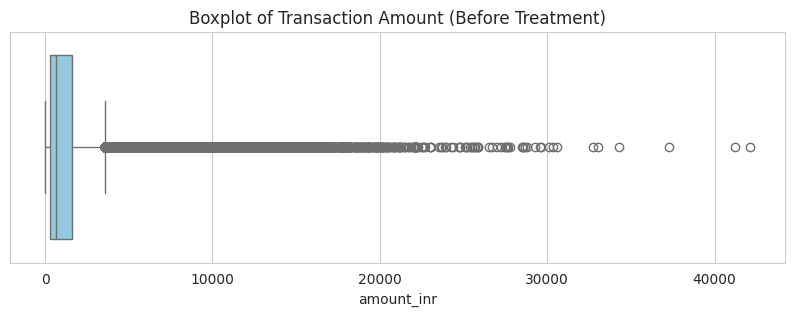

In [ ]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=df['amount_inr'], color='skyblue')
plt.title('Boxplot of Transaction Amount (Before Treatment)')
plt.show()


In [ ]:
cap_value = df['amount_inr'].quantile(0.99)
df['amount_capped'] = df['amount_inr'].clip(upper=cap_value)
print("99th percentile cap:", cap_value)
print("Max before:", df['amount_inr'].max(), "| Max after:", df['amount_capped'].max())

99th percentile cap: 9003.01000000001
Max before: 42099 | Max after: 9003.01000000001


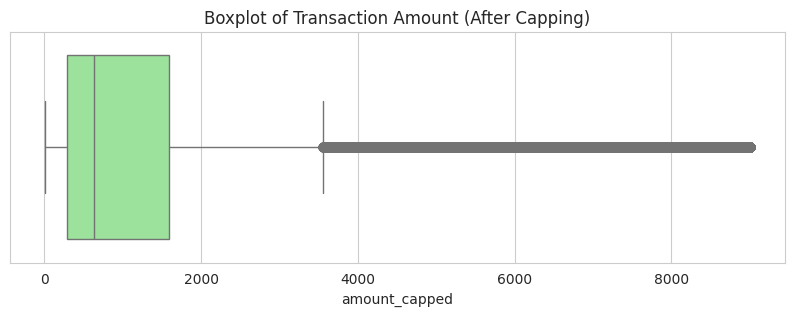

In [ ]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=df['amount_capped'], color='lightgreen')
plt.title('Boxplot of Transaction Amount (After Capping)')
plt.show()

In [ ]:
print("Skewness of amount_inr   :", round(df['amount_inr'].skew(), 3))
print("Skewness of amount_capped:", round(df['amount_capped'].skew(), 3))

Skewness of amount_inr   : 3.924
Skewness of amount_capped: 2.503


In [ ]:
df['amount_log'] = np.log1p(df['amount_inr'])
print("Skewness of amount_log:", round(df['amount_log'].skew(), 3))

Skewness of amount_log: 0.038


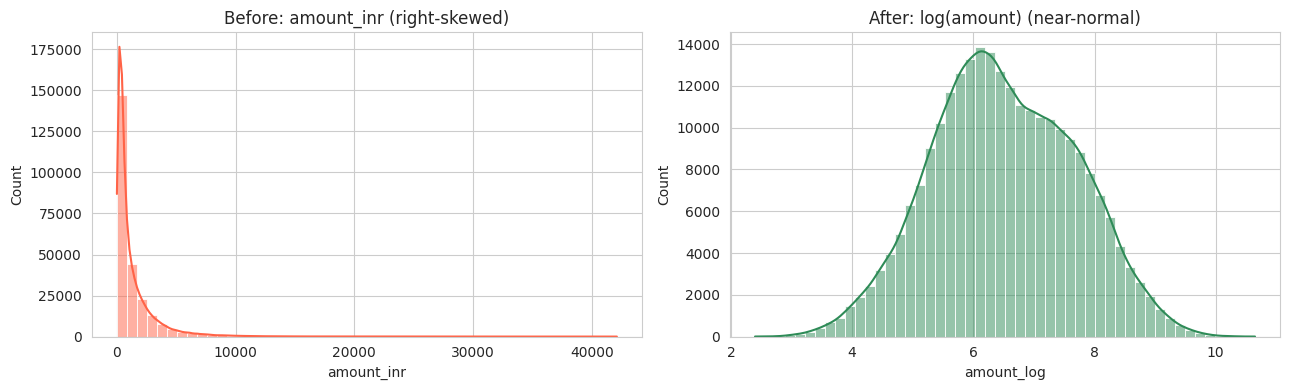

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['amount_inr'], bins=50, kde=True, ax=ax[0], color='tomato')
ax[0].set_title('Before: amount_inr (right-skewed)')
sns.histplot(df['amount_log'], bins=50, kde=True, ax=ax[1], color='seagreen')
ax[1].set_title('After: log(amount) (near-normal)')
plt.tight_layout()
plt.show()

In [ ]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

In [ ]:
cat_convert = ['transaction_type', 'merchant_category', 'transaction_status',
               'sender_age_group', 'receiver_age_group', 'sender_state',
               'sender_bank', 'receiver_bank', 'device_type',
               'network_type', 'day_of_week']
for col in cat_convert:
    df[col] = df[col].astype('category')

In [ ]:
for col in ['fraud_flag', 'is_weekend', 'hour_of_day']:
    df[col] = df[col].astype('int8')


In [ ]:
df.dtypes

,0
transaction_id,object
timestamp,datetime64[ns]
transaction_type,category
merchant_category,category
amount_inr,int64
transaction_status,category
sender_age_group,category
receiver_age_group,category
sender_state,category
sender_bank,category


In [ ]:
print("Amount <= 0        :", (df['amount_inr'] <= 0).sum())
print("Hour outside 0-23  :", (~df['hour_of_day'].between(0, 23)).sum())
print("Invalid fraud_flag :", (~df['fraud_flag'].isin([0, 1])).sum())
print("Invalid is_weekend :", (~df['is_weekend'].isin([0, 1])).sum())
print("Hour mismatch      :", (df['timestamp'].dt.hour != df['hour_of_day']).sum())
print("Weekday mismatch   :", (df['timestamp'].dt.day_name() != df['day_of_week'].astype(str)).sum())
print("Weekend mismatch   :", ((df['timestamp'].dt.dayofweek >= 5).astype('int8') != df['is_weekend']).sum())

Amount <= 0        : 0
Hour outside 0-23  : 0
Invalid fraud_flag : 0
Invalid is_weekend : 0
Hour mismatch      : 0
Weekday mismatch   : 0
Weekend mismatch   : 0


In [ ]:
df['date'] = df['timestamp'].dt.date
df['day'] = df['timestamp'].dt.day
df['month'] = df['timestamp'].dt.month
df['month_name'] = df['timestamp'].dt.month_name()
df['quarter'] = 'Q' + df['timestamp'].dt.quarter.astype(str)
df[['timestamp', 'date', 'day', 'month', 'month_name', 'quarter']].head()

,timestamp,date,day,month,month_name,quarter
0,2024-10-08 15:17:28,2024-10-08,8,10,October,Q4
1,2024-04-11 06:56:00,2024-04-11,11,4,April,Q2
2,2024-04-02 13:27:18,2024-04-02,2,4,April,Q2
3,2024-01-07 10:09:17,2024-01-07,7,1,January,Q1
4,2024-01-23 19:04:23,2024-01-23,23,1,January,Q1


In [ ]:
df['time_of_day'] = pd.cut(df['hour_of_day'],
                           bins=[-1, 5, 11, 16, 20, 23],
                           labels=['Night', 'Morning', 'Afternoon', 'Evening', 'Late Night'])
df[['hour_of_day', 'time_of_day']].head()

,hour_of_day,time_of_day
0,15,Afternoon
1,6,Morning
2,13,Afternoon
3,10,Morning
4,19,Evening


In [ ]:
df['amount_category'] = pd.cut(df['amount_inr'],
                               bins=[0, 500, 2000, 5000, np.inf],
                               labels=['Low', 'Medium', 'High', 'Very High'])
df[['amount_inr', 'amount_category']].head()

,amount_inr,amount_category
0,868,Medium
1,1011,Medium
2,477,Low
3,2784,High
4,990,Medium


In [ ]:
df['same_bank'] = (df['sender_bank'].astype(str) == df['receiver_bank'].astype(str)).astype('int8')
df[['sender_bank', 'receiver_bank', 'same_bank']].head()


,sender_bank,receiver_bank,same_bank
0,Axis,SBI,0
1,ICICI,Axis,0
2,Yes Bank,PNB,0
3,ICICI,PNB,0
4,Axis,Yes Bank,0


In [ ]:
df['is_failed'] = (df['transaction_status'] == 'FAILED').astype('int8')
df[['transaction_status', 'is_failed']].head()

,transaction_status,is_failed
0,SUCCESS,0
1,SUCCESS,0
2,SUCCESS,0
3,SUCCESS,0
4,SUCCESS,0


In [ ]:
print(df['time_of_day'].value_counts(), "\n")
print(df['amount_category'].value_counts(), "\n")
print("Same-bank transactions %:", round(df['same_bank'].mean() * 100, 2))

time_of_day
Evening       78142
Afternoon     70642
Morning       58162
Late Night    31434
Night         11620
Name: count, dtype: int64 

amount_category
Low          106624
Medium        94221
High          38199
Very High     10956
Name: count, dtype: int64 

Same-bank transactions %: 14.53


In [ ]:
print("Final shape   :", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicates    :", df.duplicated().sum())

Final shape   : (250000, 28)
Missing values: 0
Duplicates    : 0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 28 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   transaction_id      250000 non-null  object        
 1   timestamp           250000 non-null  datetime64[ns]
 2   transaction_type    250000 non-null  category      
 3   merchant_category   250000 non-null  category      
 4   amount_inr          250000 non-null  int64         
 5   transaction_status  250000 non-null  category      
 6   sender_age_group    250000 non-null  category      
 7   receiver_age_group  250000 non-null  category      
 8   sender_state        250000 non-null  category      
 9   sender_bank         250000 non-null  category      
 10  receiver_bank       250000 non-null  category      
 11  device_type         250000 non-null  category      
 12  network_type        250000 non-null  category      
 13  fraud_flag          250000 no

In [ ]:
df.to_csv("upi_transactions_2024_cleaned.csv", index=False)

In [ ]:
from google.colab import files
files.download("upi_transactions_2024_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Stage 3 – EDA and Visualizations

Univariate Analysis → distribution of single variables (countplot, histogram, boxplot)

Bivariate Analysis → relation between two variables (scatterplot, barplot, correlation heatmap)

Multivariate Analysis → relation among 3+ variables (pairplot, grouped analysis, pivot tables, advanced plots)

**Interpretation MUST with every visualization**

Focus on business story not just charts

Each chart must be in seperate cells.

# **Note For Kind of Analysis to be done**

**Type of Analysis**

* Descriptive Analysis (summarizing the dataset)

* Diagnostic Analysis (finding reasons behind patterns)

* Predictive Analysis (optional if forecasting required using basic stats)

* Prescriptive Analysis (recommendations for business decisions)

In [ ]:
df = pd.read_csv("/content/upi_transactions_2024_cleaned.csv")
print(df.shape)
print(df.columns.tolist())

(250000, 28)
['transaction_id', 'timestamp', 'transaction_type', 'merchant_category', 'amount_inr', 'transaction_status', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type', 'fraud_flag', 'hour_of_day', 'day_of_week', 'is_weekend', 'amount_capped', 'amount_log', 'date', 'day', 'month', 'month_name', 'quarter', 'time_of_day', 'amount_category', 'same_bank', 'is_failed']


In [ ]:
df.dtypes

,0
transaction_id,object
timestamp,object
transaction_type,object
merchant_category,object
amount_inr,int64
transaction_status,object
sender_age_group,object
receiver_age_group,object
sender_state,object
sender_bank,object


In [ ]:
required = ["timestamp","transaction_type","merchant_category","amount_inr",
            "transaction_status","network_type","fraud_flag","hour_of_day","day_of_week"]
print("Missing columns:", [c for c in required if c not in df.columns])

Missing columns: []


In [ ]:
print(df["transaction_status"].unique())

['SUCCESS' 'FAILED']


In [ ]:
df["is_failed"] = (df["transaction_status"].astype(str).str.upper() == "FAILED").astype(int)
print(df["is_failed"].value_counts())

is_failed
0    237624
1     12376
Name: count, dtype: int64


In [ ]:
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["month"] = df["timestamp"].dt.month
print(df["month"].value_counts().sort_index())

month
1     21221
2     19759
3     21234
4     20536
5     21333
6     20628
7     21207
8     21231
9     20597
10    21252
11    20366
12    20636
Name: count, dtype: int64


### Analysis 1: Transaction Status (Univariate – Descriptive)

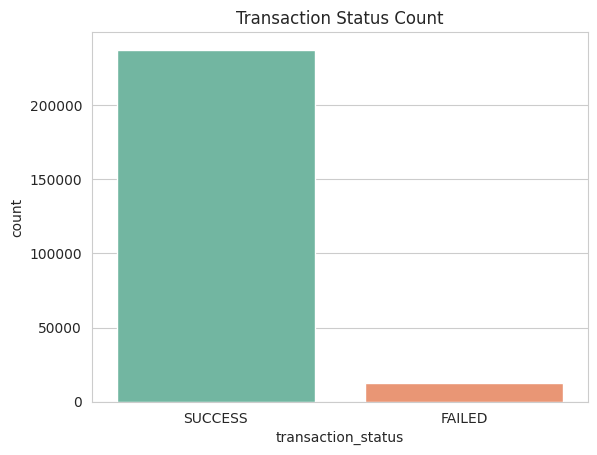

transaction_status
SUCCESS    95.05
FAILED      4.95
Name: proportion, dtype: float64


In [ ]:
sns.countplot(data=df, x="transaction_status", palette="Set2")
plt.title("Transaction Status Count")
plt.show()
print((df["transaction_status"].value_counts(normalize=True) * 100).round(2))

### **Insights**

About 95.05% of transactions succeeded and 4.95% (12,376 payments) failed
Success dominates, but 12,376 failed payments is still a large number of customers affected


## Interpretation of your above chart

Chart: Countplot of transaction status.
It shows the number of successful and failed UPI payments.
Column used: transaction_status.
From this we can say that around 4.95% of payments fail, which is the main reliability problem.

## Analysis 2: Transaction Amount Distribution (Univariate – Descriptive)

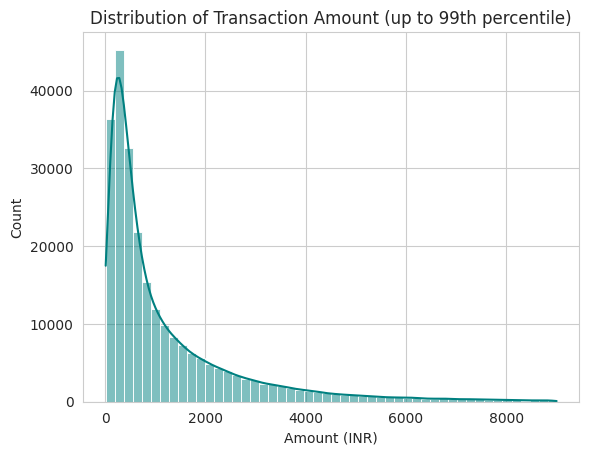

In [ ]:
q99 = df["amount_inr"].quantile(0.99)
sns.histplot(df[df["amount_inr"] <= q99]["amount_inr"], bins=50, kde=True, color="teal")
plt.title("Distribution of Transaction Amount (up to 99th percentile)")
plt.xlabel("Amount (INR)")
plt.show()

In [ ]:
print(df["amount_inr"].describe().round(2))



count    250000.00
mean       1311.76
std        1848.06
min          10.00
25%         288.00
50%         629.00
75%        1596.00
max       42099.00
Name: amount_inr, dtype: float64


## Interpretation of your above chart

Chart: Histogram of transaction amount (up to the 99th percentile).
It shows how payment values are spread.
Column used: amount_inr.
From this we can say the data is right-skewed: most payments are small (median ₹629) and the mean (₹1,312) is higher because a few very large payments pull it up (maximum ₹42,099).
Key insight: small-value payments dominate UPI usage, and the few large payments need extra monitoring.

## Analysis 3: Failure Rate by Transaction Type (Bivariate – Diagnostic)

In [ ]:
fail_type = (df.groupby("transaction_type")["is_failed"].mean() * 100).sort_values(ascending=False)
print(fail_type.round(2))

transaction_type
Recharge        5.09
P2P             4.96
P2M             4.95
Bill Payment    4.88
Name: is_failed, dtype: float64


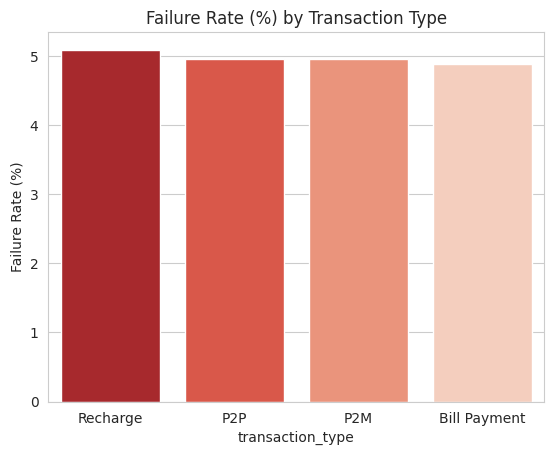

In [ ]:
sns.barplot(x=fail_type.index, y=fail_type.values, palette="Reds_r")
plt.title("Failure Rate (%) by Transaction Type")
plt.ylabel("Failure Rate (%)")
plt.show()

## Interpretation of your above chart

Chart: Barplot of failure rate by transaction type.
It compares the share of failed payments in each transaction type.
Columns used: transaction_type and is_failed (created from transaction_status).
From this we can say that the highest failure rate is 5.0% for Recharge and the lowest is 4.9% for Bill Payment, a very small gap.
Key insight: failures are fairly even across types, so transaction type alone does not explain them and other factors (such as network) must be checked.




## Analysis 4: Correlation Between Numeric Columns (Bivariate – Diagnostic)


In [ ]:
cols = [c for c in ["amount_inr","hour_of_day","is_weekend","fraud_flag","is_failed","month"] if c in df.columns]
corr = df[cols].apply(pd.to_numeric, errors="coerce").corr().round(2)
print(corr)

             amount_inr  hour_of_day  is_weekend  fraud_flag  is_failed  month
amount_inr         1.00         -0.0       -0.00         0.0       0.01   0.00
hour_of_day       -0.00          1.0        0.00         0.0      -0.00   0.00
is_weekend        -0.00          0.0        1.00         0.0       0.00   0.01
fraud_flag         0.00          0.0        0.00         1.0      -0.00  -0.00
is_failed          0.01         -0.0        0.00        -0.0       1.00  -0.00
month              0.00          0.0        0.01        -0.0      -0.00   1.00


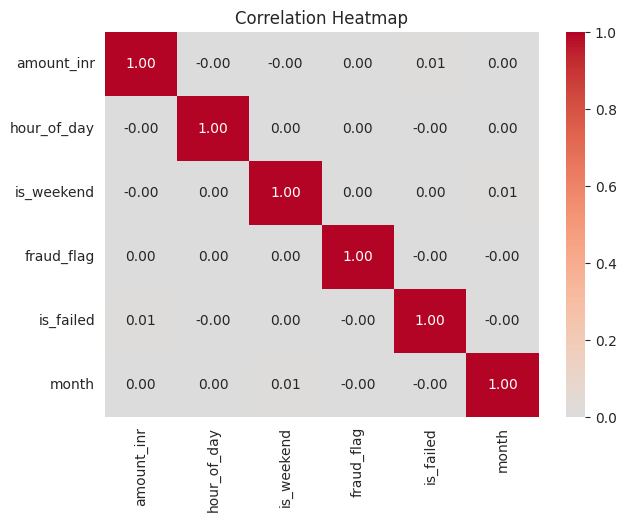

In [ ]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

## Interpretation of your above chart

Chart: Correlation heatmap of numeric columns.
It shows how strongly the columns move together (1 means a perfect link, 0 means no link).
Columns used: amount_inr, hour_of_day, is_weekend, fraud_flag, is_failed and month.
From this we can say all correlations are close to 0, so no single number column explains failure or fraud.
Key insight: failures and fraud cannot be predicted from amount or time alone, so a combination of factors such as network type and transaction type must be checked.


## Analysis 5: Failure Rate by Transaction Type and Network (Multivariate – Diagnostic)


In [ ]:
pivot_fail = (df.pivot_table(index="transaction_type", columns="network_type",
                             values="is_failed", aggfunc="mean") * 100).round(2)
print(pivot_fail)


network_type        3G    4G    5G  WiFi
transaction_type                        
Bill Payment      4.57  4.99  4.74  4.71
P2M               5.08  4.94  4.94  4.95
P2P               5.42  5.00  4.76  4.96
Recharge          6.52  5.05  5.43  3.75


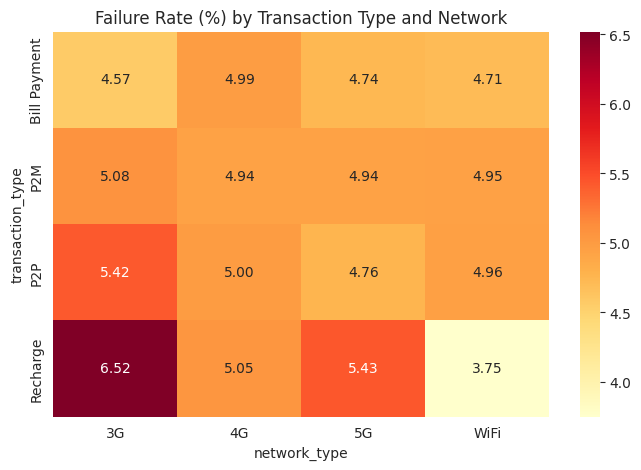

In [ ]:
plt.figure(figsize=(8, 5))
sns.heatmap(pivot_fail, annot=True, fmt=".2f", cmap="YlOrRd")
plt.title("Failure Rate (%) by Transaction Type and Network")
plt.show()

In [ ]:
print("Highest:")
print(pivot_fail.stack().sort_values(ascending=False).head(1))
print("Lowest:")
print(pivot_fail.stack().sort_values().head(1))

Highest:
transaction_type  network_type
Recharge          3G              6.52
dtype: float64
Lowest:
transaction_type  network_type
Recharge          WiFi            3.75
dtype: float64


## Interpretation of your above chart

Chart: Heatmap of failure rate (%) by transaction type and network type.
It shows where failed payments are concentrated across combinations of type and network.
Columns used: transaction_type, network_type and is_failed.
From this we can say the highest failure rate is 6.52% for Recharge on 3G and the lowest is 3.75% for Recharge on WiFi.
Key insight: 3G connections show the highest failure rates and WiFi the lowest, so network quality has a clear effect on payment success.



## Type of Analysis: Descriptive




In [ ]:
df.describe()


,timestamp,amount_inr,fraud_flag,hour_of_day,is_weekend,amount_capped,amount_log,day,month,same_bank,is_failed
count,250000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000
mean,2024-07-01 15:57:20.438195456,1311.756036,0.001920,14.681032,0.285348,1278.738044,6.503329,15.722748,6.499464,0.145284,0.049504
min,2024-01-01 00:05:10,10.000000,0.000000,0.000000,0.000000,10.000000,2.397895,1.000000,1.000000,0.000000,0.000000
25%,2024-04-01 15:12:57.249999872,288.000000,0.000000,11.000000,0.000000,288.000000,5.666427,8.000000,4.000000,0.000000,0.000000
50%,2024-07-01 14:34:17,629.000000,0.000000,15.000000,0.000000,629.000000,6.445720,16.000000,7.000000,0.000000,0.000000
75%,2024-09-30 18:13:45,1596.000000,0.000000,19.000000,1.000000,1596.000000,7.375882,23.000000,9.000000,0.000000,0.000000
max,2024-12-30 23:55:40,42099.000000,1.000000,23.000000,1.000000,9003.010000,10.647803,31.000000,12.000000,1.000000,1.000000
std,NaN,1848.059224,0.043776,5.188304,0.451581,1633.438809,1.183422,8.790647,3.442371,0.352388,0.216918


## Type of Analysis: Diagnostic


In [ ]:
fail_network = (df.groupby("network_type")["is_failed"].mean() * 100).round(2)
print(fail_network.sort_values(ascending=False))

network_type
3G      5.22
4G      4.98
5G      4.86
WiFi    4.86
Name: is_failed, dtype: float64


In [ ]:
fail_hour = (df.groupby("hour_of_day")["is_failed"].mean() * 100).round(2)
print(fail_hour)


hour_of_day
0     5.37
1     5.35
2     5.16
3     5.02
4     5.13
5     4.54
6     5.40
7     4.88
8     5.01
9     4.81
10    5.19
11    4.96
12    5.00
13    4.77
14    4.97
15    5.12
16    4.66
17    4.97
18    4.85
19    5.15
20    4.88
21    4.75
22    5.03
23    4.78
Name: is_failed, dtype: float64


In [ ]:
fraud_type = (df.groupby("transaction_type")["fraud_flag"].mean() * 100).round(3)
print(fraud_type)


transaction_type
Bill Payment    0.206
P2M             0.191
P2P             0.183
Recharge        0.239
Name: fraud_flag, dtype: float64


## Type of Analysis: Predictive (basic stats)


In [ ]:
monthly = df.groupby("month").size()
slope, intercept = np.polyfit(monthly.index.values, monthly.values, 1)
print("Trend per month:", round(slope, 1))
print("Forecast for month 13:", round(slope * 13 + intercept))


Trend per month: -0.9
Forecast for month 13: 20827


Monthly transaction volume is almost flat (trend of -0.9 transactions per month), so the forecast for month 13 is about 20,827 transactions, close to the monthly average.

## Type of Analysis: Prescriptive (recommendations)
1. Improve reliability on 3G connections, where the failure rate is highest.
2. Review the hours with the highest failure rates and add capacity there.
3. Apply extra verification for very high-value transactions, which are rare but large.
4. Track the failure rate and fraud rate every month on a dashboard.


## **Steps to Download your cleaned data for dashboard creation using Power BI**


In [ ]:
from google.colab import files
df.to_csv("upi_cleaned.csv", index=False)
files.download("upi_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Dashboard 1: UPI Payment Behaviour, Failure & Fraud Analytics(2024)**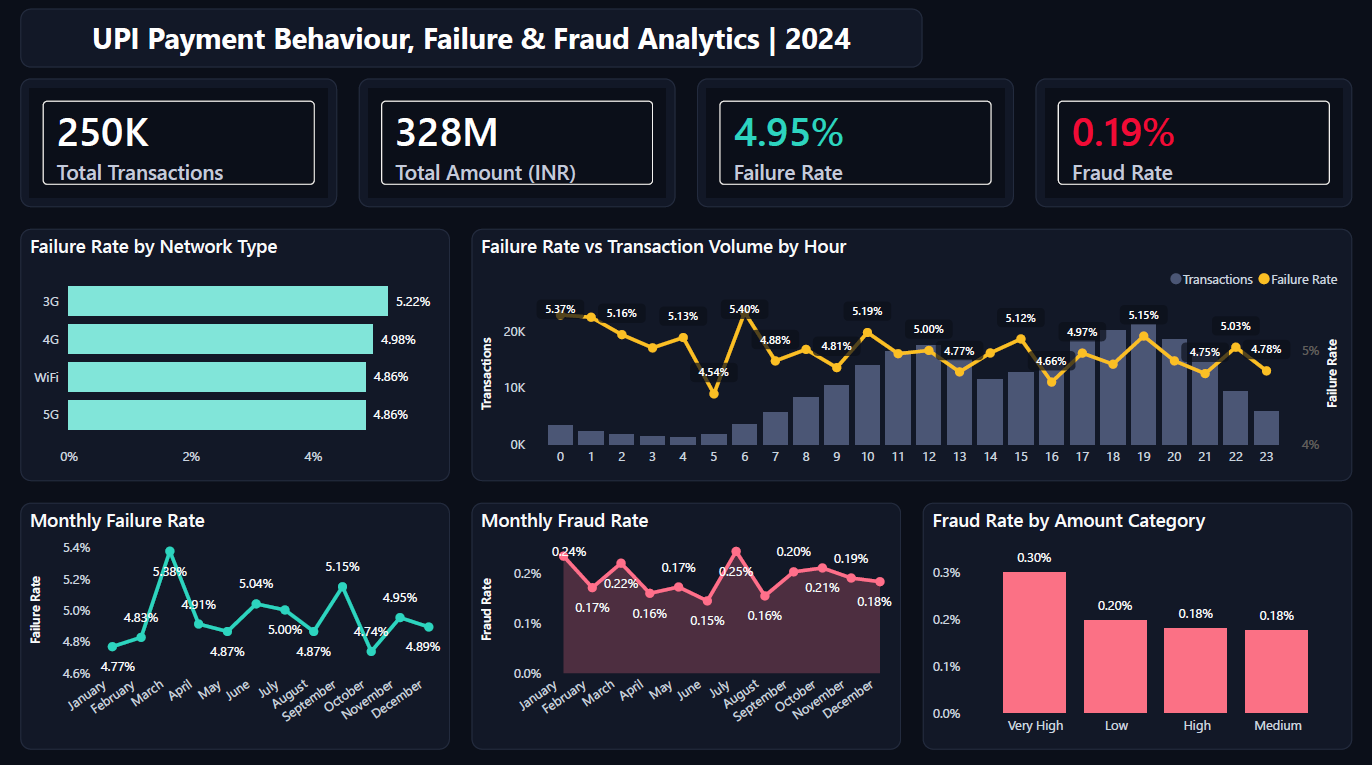

**Dashboard 2: UPI Customer, Merchant and Bank Behaviour Analytics (2024)**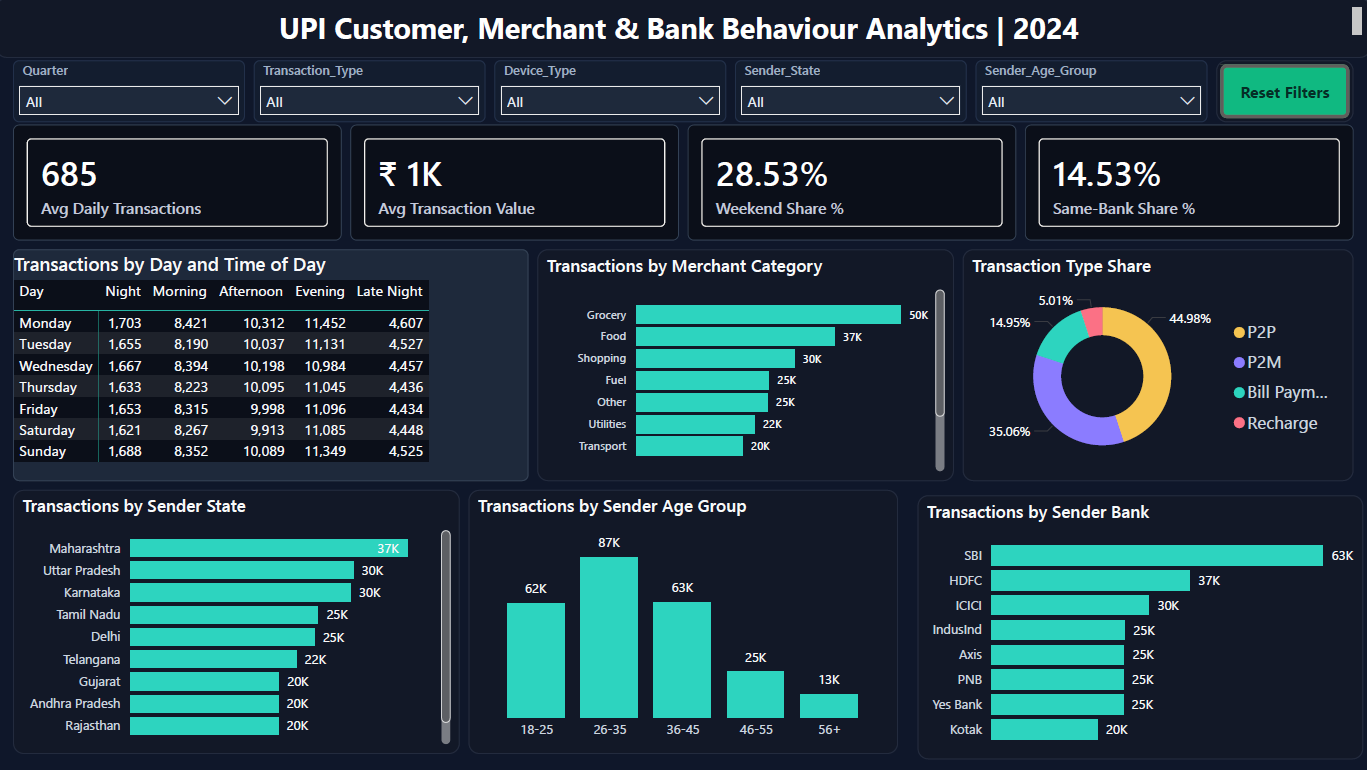

## Stage 4 – Documentation, Insights and Presentation

**Show a dashboard aligning all the charts in Power BI**

- Dashboard 1 covers payment behaviour, failure and fraud: 4 KPI cards and 5 charts
- Dashboard 2 covers customer, merchant and bank behaviour: 5 slicers, 4 KPI cards, 1 matrix and 5 charts
- Both were built in Power BI on the cleaned dataset (250,000 transactions)

**Summarize findings in plain English**

- 250K transactions worth 328M INR were analysed, with a 4.95% failure rate and a 0.19% fraud rate
- Failures are highest on 3G and lowest on 5G and WiFi
- Fraud is highest for very high-value transactions
- Most payments happen in the afternoon and evening, mainly for groceries, food and shopping
- Most users are aged 18 to 45, and only 14.53% of payments are between accounts of the same bank

**Highlight 3–5 key insights**

1. 3G has the highest failure rate (5.22%), while 5G and WiFi have the lowest (4.86%)
2. Failure peaks in March (5.38%) and fraud peaks in July (0.25%)
3. Very High amount transactions have the highest fraud rate (0.30%), against 0.18% for High and Medium
4. Evening (31%) and afternoon (28%) carry about 60% of all transactions
5. The 26-35 age group is the largest (35%), and SBI, HDFC and ICICI send 52% of transactions

**Provide recommendations for business or decision-making**

1. Improve network reliability and retry options for 3G users
2. Add stronger verification for very high-value transactions
3. Add server capacity for afternoon and evening traffic
4. Run evening merchant offers for Grocery, Food and Shopping
5. Monitor failure rate monthly (March) and fraud rate monthly (July)

**Explain the FINAL STORY WITH THE DASHBOARD/report**

- UPI is a daily habit, mainly for young working-age users
- Usage peaks in the afternoon and evening, and is mostly for everyday spending
- Payment failures depend on network type, and fraud risk rises with transaction amount
- The business should add peak-hour capacity, improve 3G reliability and strengthen checks on high-value payments




**Dashboard 1: UPI Payment Behaviour, Failure & Fraud Analytics (2024)**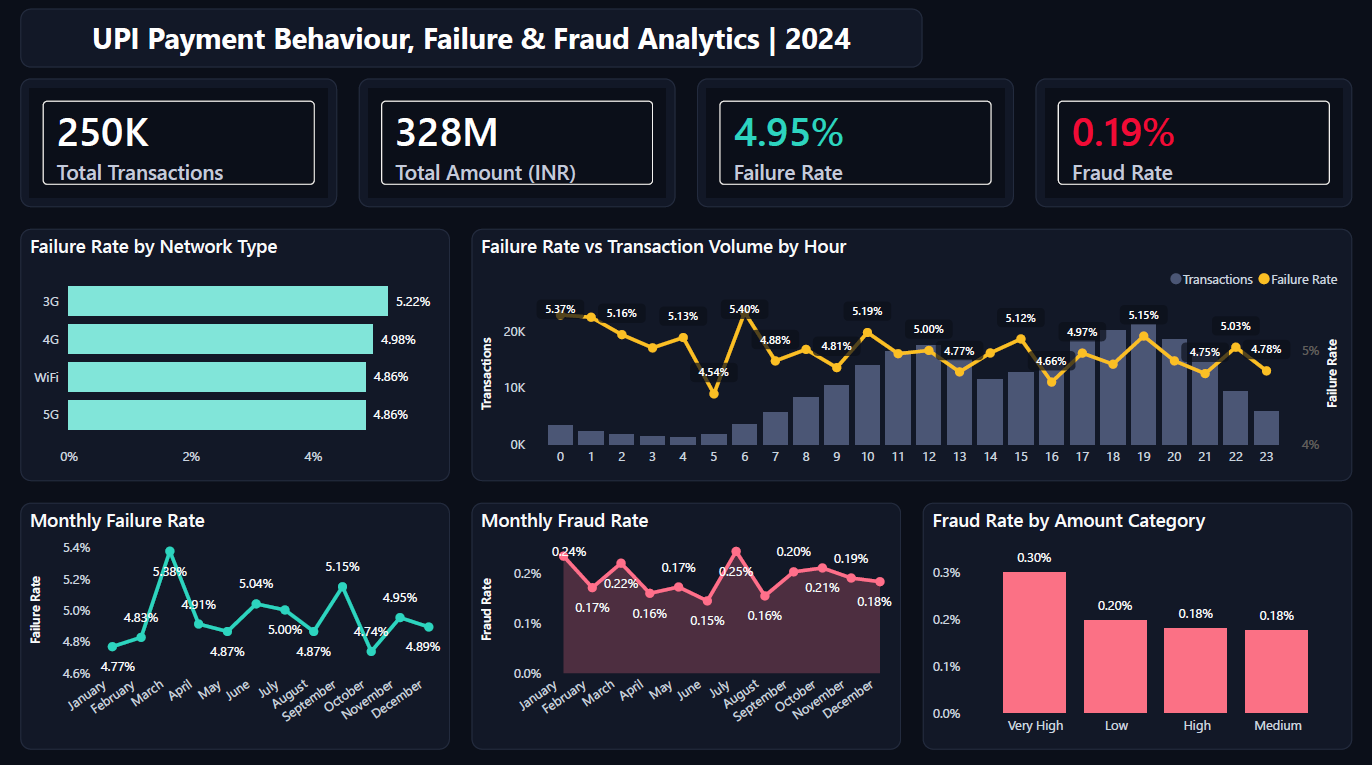

**Dashboard 2: UPI Customer, Merchant and Bank Behaviour Analytics (2024)**

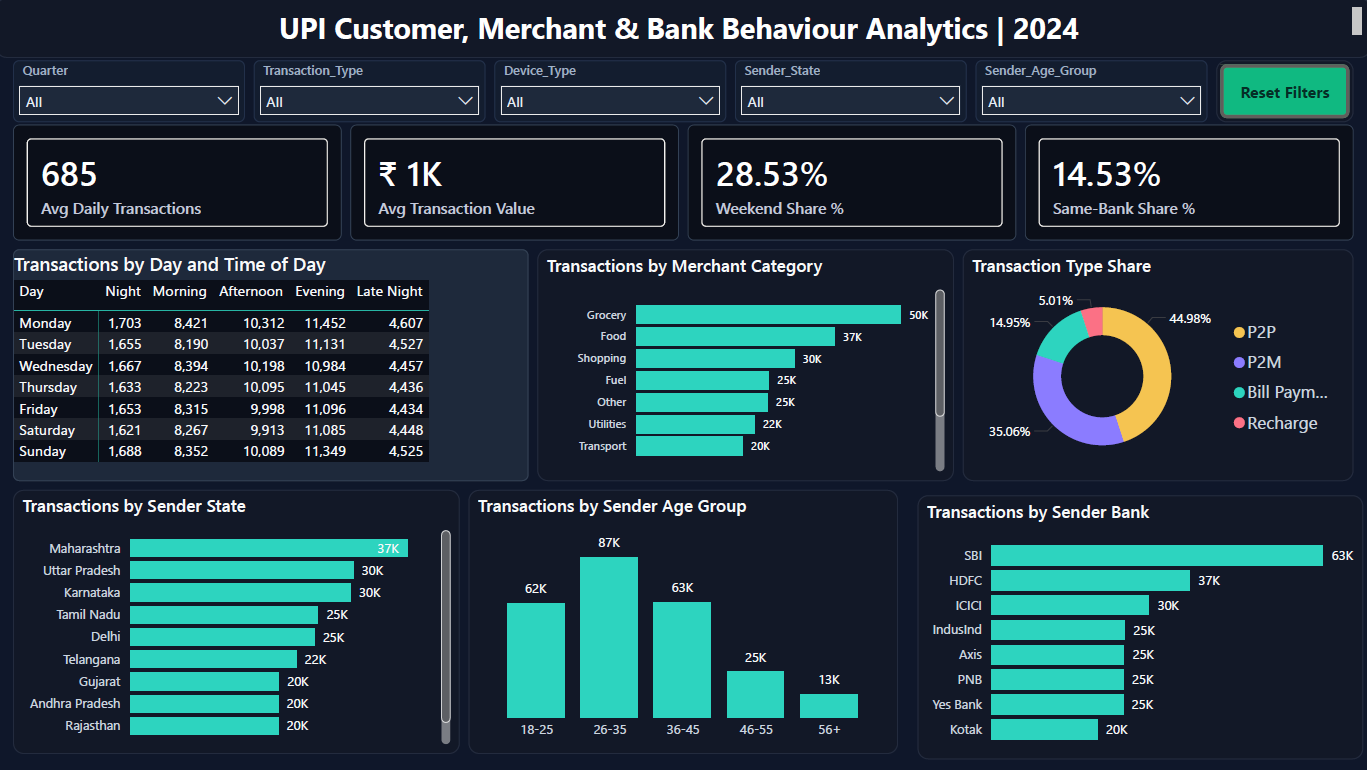

**[Python project Documentation Link](https://drive.google.com/drive/folders/17Dr9jtVSJOqh4Jj8NpS_WpN_r_1GmBBy?usp=sharing)**


## **Final Overall Insights:**
* **Descriptive (what happened):** 250K transactions worth 328M INR, with a 4.95% failure rate and a 0.19% fraud rate. Evening is the busiest time, P2P and P2M make up about 80% of payments, and Grocery is the top category
- **Diagnostic (why it happened):** 3G has the highest failure rate (5.22%), which points to network quality. Very High amount transactions have the highest fraud rate (0.30%), which shows higher risk on large payments
- **Predictive (what may happen):** If these patterns continue, evening demand will stay the highest and failures will stay higher on weaker networks. Failure peaks (March) and fraud peaks (July) may repeat
- **Prescriptive (what to do):** Improve 3G reliability, add checks on very high-value transactions, add capacity for peak hours and run evening merchant offers

# Future Enhancement

- Use a larger or more recent dataset for deeper insights
- Automate parts of the analysis with scripts or dashboards
- Add advanced visualizations and interactive dashboards in Power BI or Tableau
- Extend the analysis to predictive modeling for forecasting if needed
- Add bank-wise failure and fraud analysis to find weak points
- Add alerts for high-failure hours and high-value transactions

# Conclusion

From the analysis of 250,000 UPI transactions in 2024, we found clear patterns: payments peak in the afternoon and evening, usage is steady across all days of the week, everyday categories such as Grocery, Food and Shopping lead, and young adults aged 18 to 45 are the main users. A small number of banks and states carry most of the traffic, and most payments cross bank boundaries. These findings give a strong foundation for decisions on capacity planning, merchant offers, targeted marketing and reliability monitoring.